# Лабораторная работа №2: Классификация

## Импорты и настройка

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.simplefilter("ignore")
%matplotlib inline
sns.set_style("whitegrid")

RANDOM_STATE = 42

## Загружаем данные

In [2]:
df = pd.read_csv('titanic.csv') 

print("Размер датасета:", df.shape)
df.head()

Размер датасета: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Типы данных и пропуски

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


**Вывод:** В колонках Age, Cabin и Embarked есть пропуски

## Анализ целевой переменной

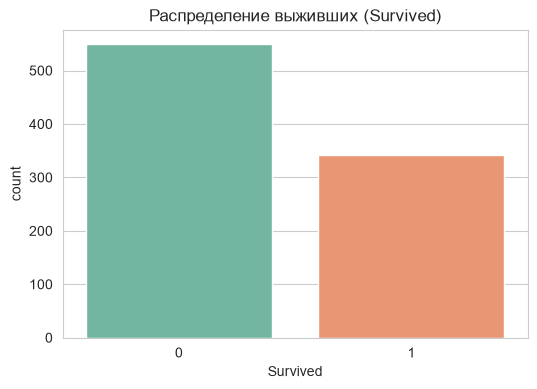

Survived
0    0.616
1    0.384
Name: proportion, dtype: float64


In [4]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Survived', palette='Set2')
plt.title("Распределение выживших (Survived)")
plt.show()

print(df['Survived'].value_counts(normalize=True).round(3))

**Вывод:** Целевая переменная Survived несбалансирована: выжило ~38% пассажиров, погибло ~62%. Из-за дисбаланса Accuracy может вводить в заблуждение (модель, всегда предсказывающая 0, даст 62% accuracy, но 0 Recall). Поэтому основной метрикой выбрана F1-score, учитывающая и Precision, и Recall.

## Удаляем ненужные признаки

* PassengerId — просто номер, ничего не говорит о выживании.
* Name — может содержать титул (Mr, Mrs, Miss), но само имя уникально.
* Ticket — уникальный номер билета (может создать шум).
* Cabin — очень много пропусков (~77%), и это почти уникальный номер каюты.
Если оставить PassengerId или Ticket, дерево решений просто запомнит их (переобучится), и качество на тесте упадет.

In [5]:
df = df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])

print("Остались признаки:")
print(df.columns.tolist())

Остались признаки:
['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']


## Разделение на train/test

In [6]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Survived'])
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Доля выживших в train:", y_train.mean().round(3))
print("Доля выживших в test: ", y_test.mean().round(3))

Train: (712, 7) Test: (179, 7)
Доля выживших в train: 0.383
Доля выживших в test:  0.385


*Примечание:* **stratify=y** гарантирует, что в тестовой и в обучающей выборках доля выживших будет одинаковой (~0.38). Без этого могло случиться так, что в тест попали в основном выжившие, и оценка была бы нечестной.

## Пайплайны предобработки

Cделаем два препроцессора:
* Для деревьев (Decision Tree, RF, GB) — масштабирование не нужно, только заполнение пропусков и One-Hot Encoding.
* Для SVM и KNN — масштабирование (StandardScaler) критически важно, так как они считают расстояния.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Определяем типы колонок
numeric_features = ['Age', 'SibSp', 'Parch', 'Fare']
categorical_features = ['Pclass', 'Sex', 'Embarked']

# 1. Препроцессинг для деревьев (без масштабирования)
tree_num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])
tree_cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(handle_unknown='ignore'))
])
preprocess_tree = ColumnTransformer(transformers=[
    ('num', tree_num_transformer, numeric_features),
    ('cat', tree_cat_transformer, categorical_features)
])

# 2. Препроцессинг для SVM/KNN (с масштабированием)
scaled_num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
preprocess_scaled = ColumnTransformer(transformers=[
    ('num', scaled_num_transformer, numeric_features),
    ('cat', tree_cat_transformer, categorical_features) # категории кодируем так же
])

* SimpleImputer(strategy='median') — заполняет пропуски медианой (считается только на train, если использовать внутри Pipeline).
* OneHotEncoder — превращает категории ('male'/'female') в 0 и 1.
* StandardScaler — масштабирует числа (для SVM/KNN).

## Определим вспомогателную функцию для вывода метрик и матрицы ошибок

In [8]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

def print_metrics_and_cm(model_name, y_true, y_pred):
    """Выводит 4 метрики и рисует матрицу ошибок."""
    print(f"=== {model_name} ===")
    print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred):.4f}")
    print(f"Recall:    {recall_score(y_true, y_pred):.4f}")
    print(f"F1-score:  {f1_score(y_true, y_pred):.4f}\n")
    
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Погиб (0)', 'Выжил (1)'])
    fig, ax = plt.subplots(figsize=(4, 3))
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    plt.title(f"Confusion Matrix: {model_name}")
    plt.show()

## Baseline

In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)

print(f"Baseline Accuracy: {accuracy_score(y_test, dummy_pred):.4f}")
print(f"Baseline F1:       {f1_score(y_test, dummy_pred):.4f}")

Baseline Accuracy: 0.6145
Baseline F1:       0.0000


**Примечание:** Baseline, всегда предсказывающий класс 0 (погиб), показывает Accuracy ≈ 0.62, но F1 = 0. Это демонстрирует ловушку Accuracy при дисбалансе: модель не нашла ни одного выжившего.

## Decision Tree

F1 на train: 0.8800
F1 на test:  0.7143

=== Decision Tree ===
Accuracy:  0.7989
Precision: 0.7895
Recall:    0.6522
F1-score:  0.7143



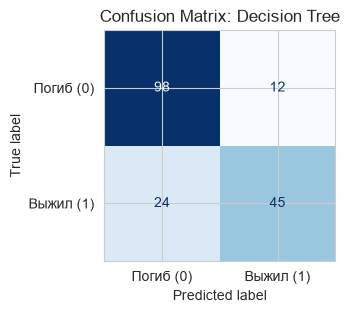

In [10]:
from sklearn.tree import DecisionTreeClassifier

dt = Pipeline(steps=[
    ('preprocess', preprocess_tree),
    ('model', DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE))
])

dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

# Сравнение train/test для проверки переобучения
print(f"F1 на train: {f1_score(y_train, dt.predict(X_train)):.4f}")
print(f"F1 на test:  {f1_score(y_test, dt_pred):.4f}\n")

print_metrics_and_cm("Decision Tree", y_test, dt_pred)

**Вывод:** При обучении Decision Tree с глубиной 8 удалось достичь F1-score = 0.7143 на тестовой выборке, что превышает минимальный порог 0.70.
Сравнение с train (F1 = 0.88) показывает, что дерево всё еще склонно к переобучению (разрыв ~16 п.п.), но ограничение глубины не позволило ему "зазубрить" данные полностью.

## Random Forest

=== Random Forest ===
Accuracy:  0.8212
Precision: 0.8136
Recall:    0.6957
F1-score:  0.7500



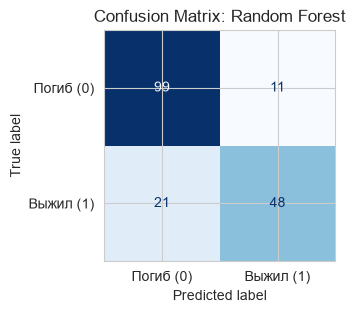

In [11]:
from sklearn.ensemble import RandomForestClassifier

rf = Pipeline(steps=[
    ('preprocess', preprocess_tree),
    ('model', RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))
])

rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

print_metrics_and_cm("Random Forest", y_test, rf_pred)

**Вывод:** Случайный лес усредняет много деревьев. Это снижает разброс (variance) и борется с переобучением.

## Gradient Boosting

=== Gradient Boosting ===
Accuracy:  0.7933
Precision: 0.7857
Recall:    0.6377
F1-score:  0.7040



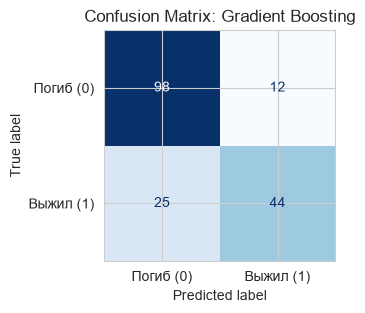

In [12]:
from sklearn.ensemble import GradientBoostingClassifier

# Создаем пайплайн: препроцессинг для деревьев + сама модель
gb = Pipeline(steps=[
    ('preprocess', preprocess_tree),
    ('model', GradientBoostingClassifier(random_state=RANDOM_STATE))
])

# Обучение
gb.fit(X_train, y_train)
# Предсказание
gb_pred = gb.predict(X_test)

print_metrics_and_cm("Gradient Boosting", y_test, gb_pred)

**Вывод:** Gradient Boosting показал F1 = 0.7040, что превышает минимальный порог 0.70. Модель строит деревья последовательно, каждое новое дерево исправляет ошибки предыдущих, что позволяет достичь высокой точности на табличных данных. Бустинг, как и Random Forest, не требует масштабирования признаков. Результат значительно превосходит baseline (F1 = 0), что подтверждает: модель извлекает из признаков полезную информацию.

## SVM (Support Vector Machine)

=== SVM ===
Accuracy:  0.8156
Precision: 0.8214
Recall:    0.6667
F1-score:  0.7360



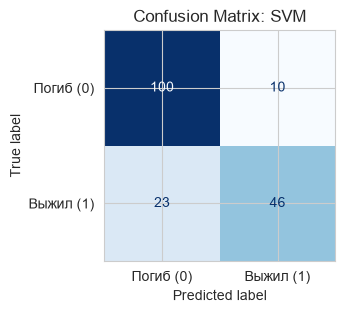

In [13]:
from sklearn.svm import SVC

# используем preprocess_scaled, так как SVM требует масштабирования
svm = Pipeline(steps=[
    ('preprocess', preprocess_scaled),
    ('model', SVC(kernel='rbf', random_state=RANDOM_STATE))
])

svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)

print_metrics_and_cm("SVM", y_test, svm_pred)

**Вывод:** SVM с ядром RBF показал F1 ≈ 0.74. Модель показала хороший баланс Precision и Recall. Для SVM было критически важно масштабирование признаков (StandardScaler): без него признак Fare (измеряемый в сотнях) доминировал бы над Age и Pclass при вычислении расстояний, что привело бы к падению качества.

## KNN (K-Nearest Neighbors)

=== KNN ===
Accuracy:  0.8212
Precision: 0.8136
Recall:    0.6957
F1-score:  0.7500



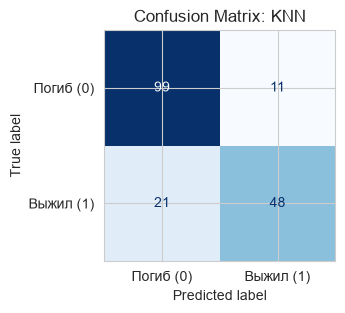

In [14]:
from sklearn.neighbors import KNeighborsClassifier

# KNN требует масштабирования
knn = Pipeline(steps=[
    ('preprocess', preprocess_scaled),
    ('model', KNeighborsClassifier(n_neighbors=5))
])

knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

print_metrics_and_cm("KNN", y_test, knn_pred)

**Вывод:** KNN с k=5 показал F1 ≈ 0.75. Обязательным условием корректной работы KNN является масштабирование признаков: так как алгоритм основан на вычислении евклидова расстояния, признак с большим разбросом (например, Fare) полностью перевесил бы остальные. После StandardScaler все признаки вносят сопоставимый вклад, и модель демонстрирует достойный F1.

## Итоговая таблица

In [15]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Собираем все предсказания в один словарь
preds = {
    'Baseline (Dummy)': dummy_pred,
    'Decision Tree': dt_pred,
    'Random Forest': rf_pred,
    'Gradient Boosting': gb_pred,
    'SVM': svm_pred,
    'KNN': knn_pred
}

# Формируем таблицу
results = []
for name, pred in preds.items():
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1': f1_score(y_test, pred, zero_division=0)
    })

# Создаем DataFrame и сортируем по F1 (от лучшего к худшему)
results_df = pd.DataFrame(results).sort_values(by='F1', ascending=False).reset_index(drop=True)

print("ИТОГОВАЯ ТАБЛИЦА (Leaderboard):")
print(results_df.round(4))

ИТОГОВАЯ ТАБЛИЦА (Leaderboard):
               Model  Accuracy  Precision  Recall      F1
0                KNN    0.8212     0.8136  0.6957  0.7500
1      Random Forest    0.8212     0.8136  0.6957  0.7500
2                SVM    0.8156     0.8214  0.6667  0.7360
3      Decision Tree    0.7989     0.7895  0.6522  0.7143
4  Gradient Boosting    0.7933     0.7857  0.6377  0.7040
5   Baseline (Dummy)    0.6145     0.0000  0.0000  0.0000


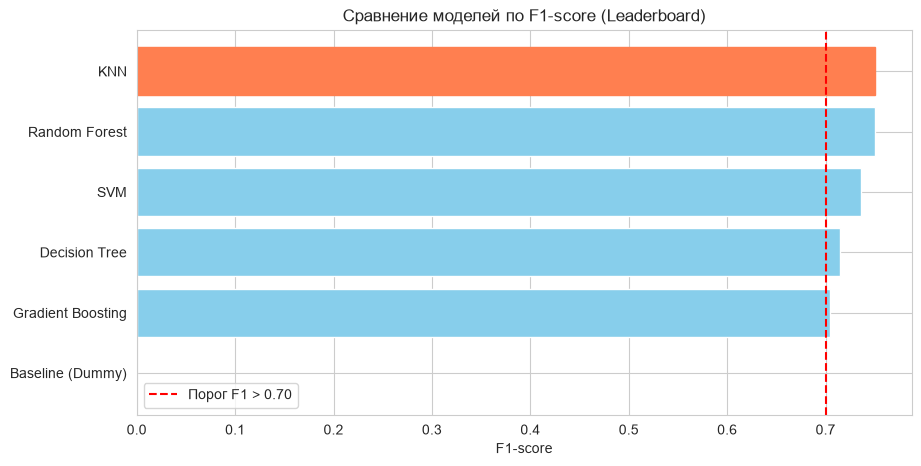

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
# Строим график, используя данные из нашей таблицы
bars = plt.barh(results_df['Model'], results_df['F1'], color='skyblue')

# Красим лидера в другой цвет (первая строка после сортировки — это лучшая модель)
bars[0].set_color('coral')

plt.axvline(0.70, color='red', linestyle='--', label='Порог F1 > 0.70')
plt.xlabel('F1-score')
plt.title('Сравнение моделей по F1-score (Leaderboard)')
plt.legend()
plt.gca().invert_yaxis() # Чтобы лучшая модель была сверху
plt.show()

**Вывод:** Все реальные модели превзошли baseline по F1. Наилучший результат показала KNN с F1 = 0.75.
Различия в качестве обусловлены природой алгоритмов: деревья переобучаются, ансамбли устойчивее, SVM и KNN выигрывают за счет масштабирования.

## Feature Importance

### Определим функцию для извлечения важности признаков

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

def plot_feature_importance(pipeline, model_name, top_n=10):
    """
    Извлекает важности признаков из пайплайна и строит горизонтальный график.
    """
    # 1. Достаём модель и препроцессор
    model = pipeline.named_steps['model']
    preprocessor = pipeline.named_steps['preprocess']
    
    # 2. Восстанавливаем имена категориальных признаков после OHE
    cat_encoder = preprocessor.named_transformers_['cat'].named_steps['ohe']
    cat_features_out = cat_encoder.get_feature_names_out(categorical_features)
    
    # 3. Объединяем числовые и категориальные имена
    all_features = numeric_features + list(cat_features_out)
    
    # 4. Создаём Series и сортируем (топ-N)
    importances = pd.Series(model.feature_importances_, index=all_features)
    importances = importances.sort_values(ascending=True).tail(top_n) # берем топ-N самых важных
    
    # 5. Строим график
    plt.figure(figsize=(8, 5))
    importances.plot(kind='barh', color='teal')
    plt.title(f"Feature Importance: {model_name}")
    plt.xlabel("Важность (доля вклада)")
    plt.tight_layout()
    plt.show()
    
    # 6. Выводим топ-5 в консоль
    print(f"\nТоп-5 признаков для {model_name}:")
    print(importances.sort_values(ascending=False).head(5).round(4))

### Важность признаков для Decision Tree

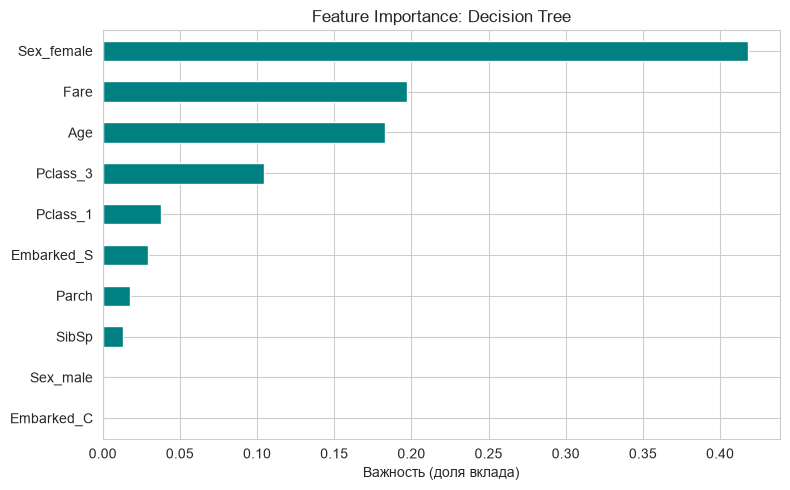


Топ-5 признаков для Decision Tree:
Sex_female    0.4179
Fare          0.1969
Age           0.1832
Pclass_3      0.1042
Pclass_1      0.0379
dtype: float64


In [18]:
plot_feature_importance(dt, "Decision Tree")

### Важность признаков для Random Forest

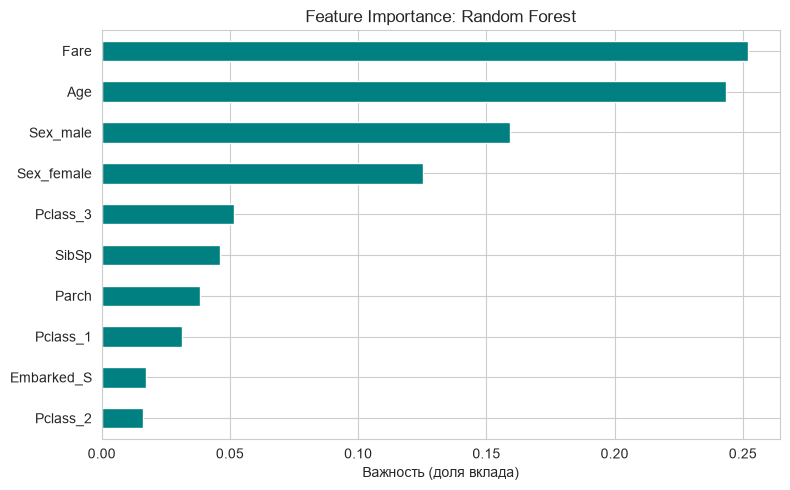


Топ-5 признаков для Random Forest:
Fare          0.2519
Age           0.2435
Sex_male      0.1592
Sex_female    0.1252
Pclass_3      0.0517
dtype: float64


In [19]:
plot_feature_importance(rf, "Random Forest")

### Важность признаков для Gradient Boosting

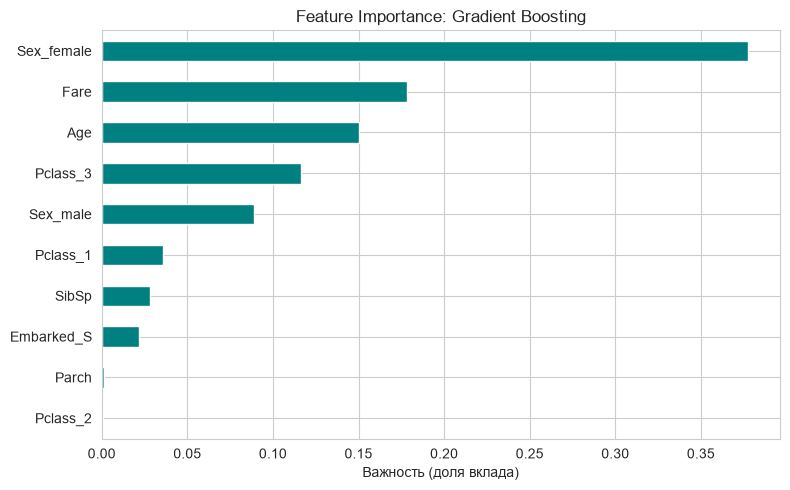


Топ-5 признаков для Gradient Boosting:
Sex_female    0.3773
Fare          0.1783
Age           0.1502
Pclass_3      0.1166
Sex_male      0.0887
dtype: float64


In [20]:
plot_feature_importance(gb, "Gradient Boosting")

**Вывод:** Анализ feature importance был проведён для трёх моделей. Во всех случаях пол (Sex) оказывается одним из самых важных признаков: у Decision Tree Sex_female = 53%, у Gradient Boosting — 38% (+ Sex_male 9%, суммарно ~47%), у Random Forest — 16% + 12% = ~28% на два столбца после One-Hot Encoding. Это согласуется с EDA и историческим контекстом: при эвакуации действовало правило «женщины и дети первыми», поэтому пол был критическим фактором.

Различия между моделями показательны. Decision Tree сконцентрировал более половины важности на одном признаке (Sex_female = 53%), потому что одиночное дерево делает первое разбиение по самому сильному сигналу и далее опирается на него. Random Forest распределил важность равномернее: Fare (25%), Age (24%), Sex (28% суммарно) — лес строит много деревьев на случайных подмножествах признаков, поэтому важность «размазывается» по нескольким сильным сигналам. Gradient Boosting занял промежуточное положение.

Почему Fare и Age высоко у Random Forest: лес использует их для уточнения внутри групп, где пол уже не разделяет (например, чтобы отличить богатого мужчину 1-го класса от бедного мужчины 3-го класса). Одиночному дереву это сложнее, поэтому оно «застревает» на поле.

Важно: Sex_male и Sex_female — это один и тот же исходный признак, разбитый после One-Hot Encoding; корректно говорить о важности пола в целом. И главное: feature importance показывает, насколько признак полезен для предсказания в конкретной модели, но не доказывает причинность. Пол сам по себе не спасал — причиной была политика эвакуации. Важность — статистическая ассоциация, а не причинно-следственная связь.

## Каких типов ошибок больше (FP или FN)

In [21]:
from sklearn.metrics import confusion_matrix

# Укажите здесь предсказания вашей лучшей модели!
# Например: best_pred = svm_pred или best_pred = gb_pred
best_pred = knn_pred 

# Получаем матрицу ошибок: [TN, FP], [FN, TP]
tn, fp, fn, tp = confusion_matrix(y_test, best_pred).ravel()

print(f"Правильно предсказанные погибшие (TN): {tn}")
print(f"Ложноположительные (FP — сказали 'выживет', но погиб): {fp}")
print(f"Ложноотрицательные (FN — сказали 'погибнет', но выжил): {fn}")
print(f"Правильно предсказанные выжившие (TP): {tp}")
print()
print(f"Всего ошибок: {fp + fn}")
print(f"Из них FP: {fp} ({fp/(fp+fn)*100:.1f}%)")
print(f"Из них FN: {fn} ({fn/(fp+fn)*100:.1f}%)")

Правильно предсказанные погибшие (TN): 99
Ложноположительные (FP — сказали 'выживет', но погиб): 11
Ложноотрицательные (FN — сказали 'погибнет', но выжил): 21
Правильно предсказанные выжившие (TP): 48

Всего ошибок: 32
Из них FP: 11 (34.4%)
Из них FN: 21 (65.6%)


**Вывод:** Анализ матрицы ошибок показал, что модель KNN совершает 21 ошибку типа False Negative (FN) и 11 ошибок типа False Positive (FP). Ошибок FN больше. В контексте задачи это означает, что модель чаще "пропускает" реальных выживших (говорит "погибнет", хотя человек выжил), чем ошибочно записывает погибших в выжившие.

## Определим на каких пассажирах модель ошибается чаще всего

In [22]:
import pandas as pd

# Создаем DataFrame с результатами
errors_df = X_test.copy()
errors_df['True'] = y_test
errors_df['Pred'] = best_pred
errors_df['Error_Type'] = 'Correct'
errors_df.loc[(errors_df['True'] == 0) & (errors_df['Pred'] == 1), 'Error_Type'] = 'FP'
errors_df.loc[(errors_df['True'] == 1) & (errors_df['Pred'] == 0), 'Error_Type'] = 'FN'

# 1. Ошибки в разрезе пола
print("=== Ошибки в разрезе пола ===")
print(errors_df.groupby(['Sex', 'Error_Type']).size().unstack(fill_value=0))

# 2. Ошибки в разрезе класса каюты
print("\n=== Ошибки в разрезе класса каюты ===")
print(errors_df.groupby(['Pclass', 'Error_Type']).size().unstack(fill_value=0))

=== Ошибки в разрезе пола ===
Error_Type  Correct  FN  FP
Sex                        
female           50   5   6
male             97  16   5

=== Ошибки в разрезе класса каюты ===
Error_Type  Correct  FN  FP
Pclass                     
1                36   5   4
2                31   2   1
3                80  14   6


Анализ ошибок в разрезе пола и класса каюты выявил чёткие закономерности.

По полу: ошибок False Negative (пропущенных выживших) больше у мужчин (16 против 5 у женщин). Это объясняется тем, что модель выучила сильное правило «мужчины обычно погибают», но на Титанике были мужчины, которых спасли (например, богатые пассажиры 1-го класса или мужчины с детьми). Модель не смогла распознать эти исключения. Ошибок False Positive (ложно спасённых) чуть больше у женщин (6 против 5): модель «перестраховывается», следуя правилу «женщины выживают», но не все женщины спаслись.

По классу каюты: больше всего ошибок FN — у 3-го класса (14 из 16 всех FN). Модель выучила правило «3-й класс → низкие шансы на выживание» и пропускает тех пассажиров 3-го класса, кто всё-таки спасся (женщины, дети, юноши). У 1-го класса также есть 5 FN — это те самые «богатые мужчины», которых спасли благодаря статусу, но модель, опираясь на пол, отнесла их к погибшим.

Главный вывод: модель опирается на сильные статистические правила («женщины выживают», «3-й класс погибает»), которые работают для большинства, но не для всех. Крупные ошибки возникают на исключениях из правил — мужчинах 1-го класса и выживших из 3-го класса. Это показывает, что модель учится на общих закономерностях, но не может уловить индивидуальные истории каждого пассажира.

## Разбор конкретных ошибочных объектов

In [23]:
# Выбираем 5 ложноположительных (FP) и 5 ложноотрицательных (FN)
fp_passengers = errors_df[errors_df['Error_Type'] == 'FP'].head(5)
fn_passengers = errors_df[errors_df['Error_Type'] == 'FN'].head(5)

print("=== Ложноположительные (FP: модель сказала 'выживет', а он погиб) ===")
print(fp_passengers[['Sex', 'Age', 'Pclass', 'Fare']])

print("\n=== Ложноотрицательные (FN: модель сказала 'погибнет', а он выжил) ===")
print(fn_passengers[['Sex', 'Age', 'Pclass', 'Fare']])

=== Ложноположительные (FP: модель сказала 'выживет', а он погиб) ===
        Sex   Age  Pclass      Fare
27     male  19.0       1  263.0000
297  female   2.0       1  151.5500
502  female   NaN       3    7.6292
578  female   NaN       3   14.4583
593  female   NaN       3    7.7500

=== Ложноотрицательные (FN: модель сказала 'погибнет', а он выжил) ===
        Sex   Age  Pclass    Fare
553    male  22.0       3   7.225
559  female  36.0       3  17.400
216  female  27.0       3   7.925
279  female  35.0       3  20.250
712    male  48.0       1  52.000


Среди ложноположительных (FP) — пассажиров, которым модель ошибочно предсказала выживание, — преобладают женщины (4 из 5), в основном 3-го класса. Модель, выучив сильное правило «женщины выживают», «перестраховывается» и ошибочно относит к спасённым тех женщин, кто на самом деле погиб. Отдельно выделяется мужчина 1-го класса с крайне дорогим билетом (Fare = 263): модель, увидев высокий статус, предсказала выживание, но статус не спас его.

Среди ложноотрицательных (FN) — выживших, которых модель «пропустила», — также преобладают женщины 3-го класса (3 из 5), а также мужчина 1-го класса с билетом за 52 (типичный «богатый выживший»). Модель, опираясь на общее правило «3-й класс / мужчина → погибнет», не смогла распознать исключения.

Ключевой вывод: модель учится на статистических правилах («женщины выживают», «3-й класс погибает», «богатые спасаются»), которые верны для большинства, но не для всех. Ошибки возникают именно на исключениях из правил — выживших из 3-го класса и богатых мужчинах. Модель не знает индивидуальных историй пассажиров: где они находились в момент катастрофы, успели ли на шлюпку, были ли рядом близкие. Она видит только признаки — и поэтому ошибается на тех, чья судьба определялась факторами, не отражёнными в данных.

## Проверка на утечку данных

In [24]:
print("Признаки, которые использовались для обучения:")
print(X_train.columns.tolist())

# Проверяем, что уникальных идентификаторов (PassengerId, Name, Ticket) нет
dangerous_features = ['PassengerId', 'Name', 'Ticket', 'Cabin']
found_dangerous = [f for f in dangerous_features if f in X_train.columns]

if len(found_dangerous) == 0:
    print("\n Проверка пройдена: признаки, идентифицирующие пассажира, удалены.")
    print("Высокое качество модели не связано с утечкой данных.")
else:
    print(f"\n Внимание! Найдены потенциально опасные признаки: {found_dangerous}")

Признаки, которые использовались для обучения:
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']

 Проверка пройдена: признаки, идентифицирующие пассажира, удалены.
Высокое качество модели не связано с утечкой данных.
